#  La Poule qui Chante - Étude de marché internationale
## Notebook 2 - ACP et Clustering

---

**Objectif :** identifier des groupements de pays pour orienter la stratégie d'export.

**Plan :**

| Étape | Contenu |
|---|---|
| 1 | Chargement et préparation des données |
| 2 | Standardisation |
| 3 | ACP - éboulis des valeurs propres |
| 4 | Cercle des corrélations |
| 5 | Projection des individus (nuage 2D) |
| 6 | CAH - Classification Ascendante Hiérarchique |
| 7 | K-means |
| 8 | Comparaison et interprétation des clusters |


## 1. Imports et chargement des données

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.figsize'] = (12, 8)
plt.rcParams['font.family'] = 'DejaVu Sans'

print('Imports OK')

Imports OK


In [2]:
# Chargement du dataset produit par le Notebook 1
df = pd.read_csv('dataset_poule_qui_chante.csv', encoding='utf-8-sig')

print(f'Dimensions : {df.shape}')
print(f'Pays : {len(df)}')
print(f'Variables : {df.columns.tolist()}')
df.head(3)

Dimensions : (170, 14)
Pays : 170
Variables : ['Zone', 'Code_ISO3', 'Volaille_Per_Capita_kg', 'Volaille_Import_Dependency', 'Volaille_Net_Import', 'Volaille_Production_Gap', 'Poultry_Share_in_Meat_Consumption', 'Viandes_Import_Dependency', 'Volaille_Import_Cover_Ratio', 'PIB_par_habitant', 'Taux_Urbanisation', 'Acces_Internet', 'Surface_Agricole', 'Population_Totale']


,Zone,Code_ISO3,Volaille_Per_Capita_kg,Volaille_Import_Dependency,Volaille_Net_Import,Volaille_Production_Gap,Poultry_Share_in_Meat_Consumption,Viandes_Import_Dependency,Volaille_Import_Cover_Ratio,PIB_par_habitant,Taux_Urbanisation,Acces_Internet,Surface_Agricole,Population_Totale
0,Afghanistan,AFG,1.53,0.5273,10.0,27.0,0.1763,0.0929,1.0741,525.469771,24.835282,13.500000,58.123668,36.30
1,Afrique du Sud,ZAF,35.69,0.2526,451.0,368.0,0.5947,0.1502,1.3967,6618.335083,63.331108,56.167400,79.417850,57.01
2,Albanie,ALB,16.36,0.8085,38.0,34.0,0.3456,0.2794,1.1176,5006.360130,55.980276,62.400002,42.856971,2.88


## 2. Sélection finale des variables pour l'ACP

Suite à l'analyse des corrélations du Notebook 1, on retire les variables redondantes :

| Variable retirée | Raison |
|---|---|
| `Volaille_Self_Sufficiency` | ≈ 1 − `Volaille_Import_Dependency` (r = −0.78) |
| `Total_Meat_Consumption` | Fortement corrélée à `Population_Totale` (r = 0.74) |

**Variables retenues pour l'ACP :**


In [3]:
vars_acp = [
    'Volaille_Per_Capita_kg',
    'Volaille_Import_Dependency',
    'Volaille_Net_Import',
    'Volaille_Production_Gap',
    'Poultry_Share_in_Meat_Consumption',
    'Viandes_Import_Dependency',
    'Volaille_Import_Cover_Ratio',
    'PIB_par_habitant',
    'Taux_Urbanisation',
    'Acces_Internet',
    'Surface_Agricole',
    'Population_Totale',
]

# Vérification stricte : on alerte si une variable attendue manque
manquantes = [v for v in vars_acp if v not in df.columns]
if manquantes:
    raise ValueError(
        f"Variables manquantes dans le CSV : {manquantes}\n"
        f"Régénère 'dataset_poule_qui_chante.csv' depuis le Notebook 1."
    )

X = df[vars_acp].copy()
pays = df['Zone'].values

print(f'Variables pour ACP : {len(vars_acp)} (attendu : 12)')
print(f'Pays : {len(X)}')
print(f'NaN : {X.isnull().sum().sum()}')

Variables pour ACP : 12 (attendu : 12)
Pays : 170
NaN : 0


In [4]:
# Exclusion des géants exportateurs (non pertinents pour une stratégie d'export)
# Brésil et USA sont des producteurs/exportateurs mondiaux dominants
# -> hors-cible pour la stratégie d'expansion de La Poule qui Chante
geants_exportateurs = ['Brésil', "États-Unis d'Amérique"]

print(f'Pays avant exclusion : {len(df)}')
df = df[~df['Zone'].isin(geants_exportateurs)].reset_index(drop=True)
print(f'Pays après exclusion : {len(df)}')

X = df[vars_acp].copy()
pays = df['Zone'].values

Pays avant exclusion : 170
Pays après exclusion : 168


## 3. Standardisation (centrage-réduction)

> **Pourquoi standardiser ?**
> Les variables ont des unités très différentes : le PIB/hab est en milliers de dollars,
> la consommation de volaille en kg, la population en millions.
> Sans standardisation, l'ACP serait dominée par les variables à grande variance.
> On centre (moyenne = 0) et on réduit (écart-type = 1) chaque variable.


In [5]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Vérification
print('Après standardisation :')
print(f'  Moyenne (doit être ≈ 0) : {X_scaled.mean(axis=0).round(10)}')
print(f'  Écart-type (doit être = 1) : {X_scaled.std(axis=0).round(2)}')

Après standardisation :
  Moyenne (doit être ≈ 0) : [ 0.  0.  0.  0.  0. -0. -0.  0. -0. -0.  0. -0.]
  Écart-type (doit être = 1) : [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


## 4. ACP - Analyse en Composantes Principales

> **Qu'est-ce que l'ACP ?**
> L'ACP transforme les variables originales (corrélées entre elles)
> en nouvelles variables **indépendantes** appelées **composantes principales**.
> Chaque composante capture une part de la variance totale du dataset.
> La 1ère composante explique le plus de variance, la 2ème le plus de variance restante, etc.

### 4.1 Calcul et éboulis des valeurs propres


In [6]:
# Calcul de l'ACP sur toutes les composantes
pca = PCA()
X_pca = pca.fit_transform(X_scaled)

# Variance expliquée par chaque composante
variance_expliquee = pca.explained_variance_ratio_ * 100
variance_cumulee = np.cumsum(variance_expliquee)

print('Variance expliquée par composante :')
for i, (ve, vc) in enumerate(zip(variance_expliquee, variance_cumulee)):
    print(f'  CP{i+1} : {ve:.1f}%  (cumulé : {vc:.1f}%)')

Variance expliquée par composante :
  CP1 : 26.9%  (cumulé : 26.9%)
  CP2 : 19.8%  (cumulé : 46.7%)
  CP3 : 14.0%  (cumulé : 60.6%)
  CP4 : 10.9%  (cumulé : 71.5%)
  CP5 : 8.8%  (cumulé : 80.3%)
  CP6 : 6.5%  (cumulé : 86.8%)
  CP7 : 4.1%  (cumulé : 90.9%)
  CP8 : 3.6%  (cumulé : 94.5%)
  CP9 : 2.2%  (cumulé : 96.7%)
  CP10 : 1.4%  (cumulé : 98.1%)
  CP11 : 1.2%  (cumulé : 99.3%)
  CP12 : 0.7%  (cumulé : 100.0%)


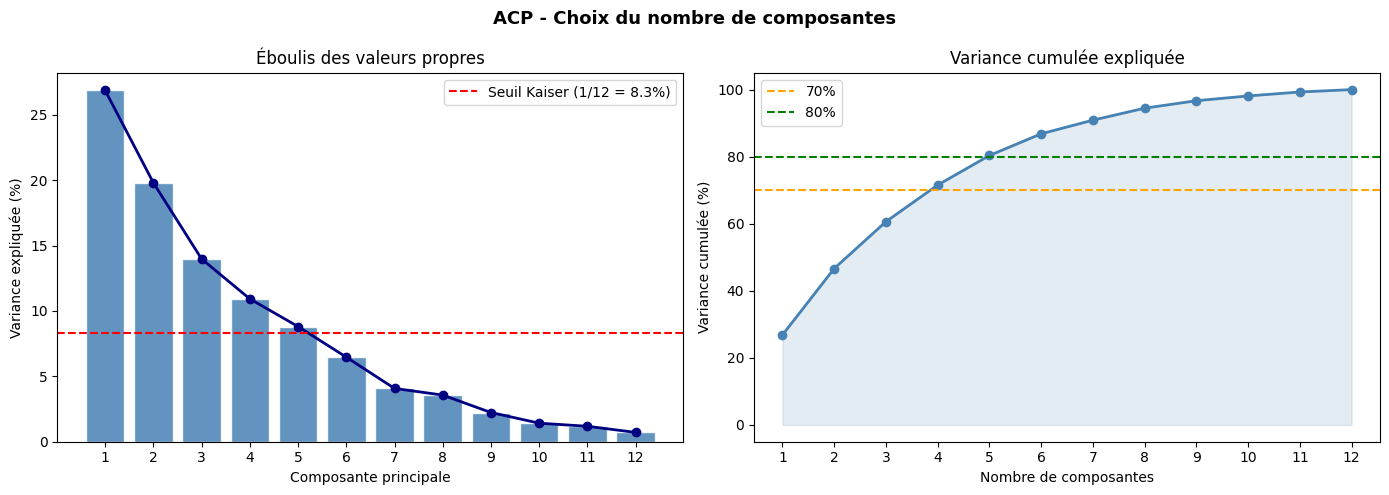

In [7]:
# Éboulis des valeurs propres (Scree plot)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Graphique 1 : variance par composante
axes[0].bar(range(1, len(variance_expliquee)+1), variance_expliquee,
            color='steelblue', edgecolor='white', alpha=0.85)
axes[0].plot(range(1, len(variance_expliquee)+1), variance_expliquee,
             'o-', color='navy', linewidth=2, markersize=6)
axes[0].axhline(y=100/len(vars_acp), color='red', linestyle='--',
                linewidth=1.5, label=f'Seuil Kaiser (1/{len(vars_acp)} = {100/len(vars_acp):.1f}%)')
axes[0].set_xlabel('Composante principale')
axes[0].set_ylabel('Variance expliquée (%)')
axes[0].set_title('Éboulis des valeurs propres')
axes[0].legend()
axes[0].set_xticks(range(1, len(variance_expliquee)+1))

# Graphique 2 : variance cumulée
axes[1].plot(range(1, len(variance_cumulee)+1), variance_cumulee,
             'o-', color='steelblue', linewidth=2, markersize=6)
axes[1].axhline(y=70, color='orange', linestyle='--', linewidth=1.5, label='70%')
axes[1].axhline(y=80, color='green', linestyle='--', linewidth=1.5, label='80%')
axes[1].fill_between(range(1, len(variance_cumulee)+1), variance_cumulee,
                     alpha=0.15, color='steelblue')
axes[1].set_xlabel('Nombre de composantes')
axes[1].set_ylabel('Variance cumulée (%)')
axes[1].set_title('Variance cumulée expliquée')
axes[1].legend()
axes[1].set_xticks(range(1, len(variance_cumulee)+1))

plt.suptitle('ACP - Choix du nombre de composantes', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('eboulis.png', dpi=120, bbox_inches='tight')
plt.show()

### 4.2 Choix du nombre de composantes

L'éboulis montre une décroissance marquée après CP3, puis un plateau. Le critère de Kaiser (valeur propre > 1, soit > 8,3 % ici) valide théoriquement 5 composantes (80,3 % de variance cumulée). Cependant, par souci de lisibilité graphique pour le cercle des corrélations et la projection des individus en 2D, on retient 3 composantes principales (CP1, CP2, CP3), qui expliquent 60,6 % de la variance totale - un niveau jugé suffisant pour interpréter les grandes tendances du nuage de pays.


In [8]:
# Adapter N_COMP selon la lecture de l'éboulis
N_COMP = 3   # ← à ajuster selon le graphique

pca_final = PCA(n_components=N_COMP)
X_pca_final = pca_final.fit_transform(X_scaled)

variance_retenue = pca_final.explained_variance_ratio_.sum() * 100
print(f'Composantes retenues : {N_COMP}')
print(f'Variance totale expliquée : {variance_retenue:.1f}%')

Composantes retenues : 3
Variance totale expliquée : 60.6%


## 5. Cercle des corrélations

> **Comment lire le cercle des corrélations ?**
> - Chaque flèche représente une variable originale
> - La **longueur** de la flèche indique la qualité de représentation (plus elle est longue, mieux la variable est représentée)
> - Deux flèches **proches** → variables corrélées positivement
> - Deux flèches **opposées** → variables corrélées négativement
> - Deux flèches **perpendiculaires** → variables indépendantes


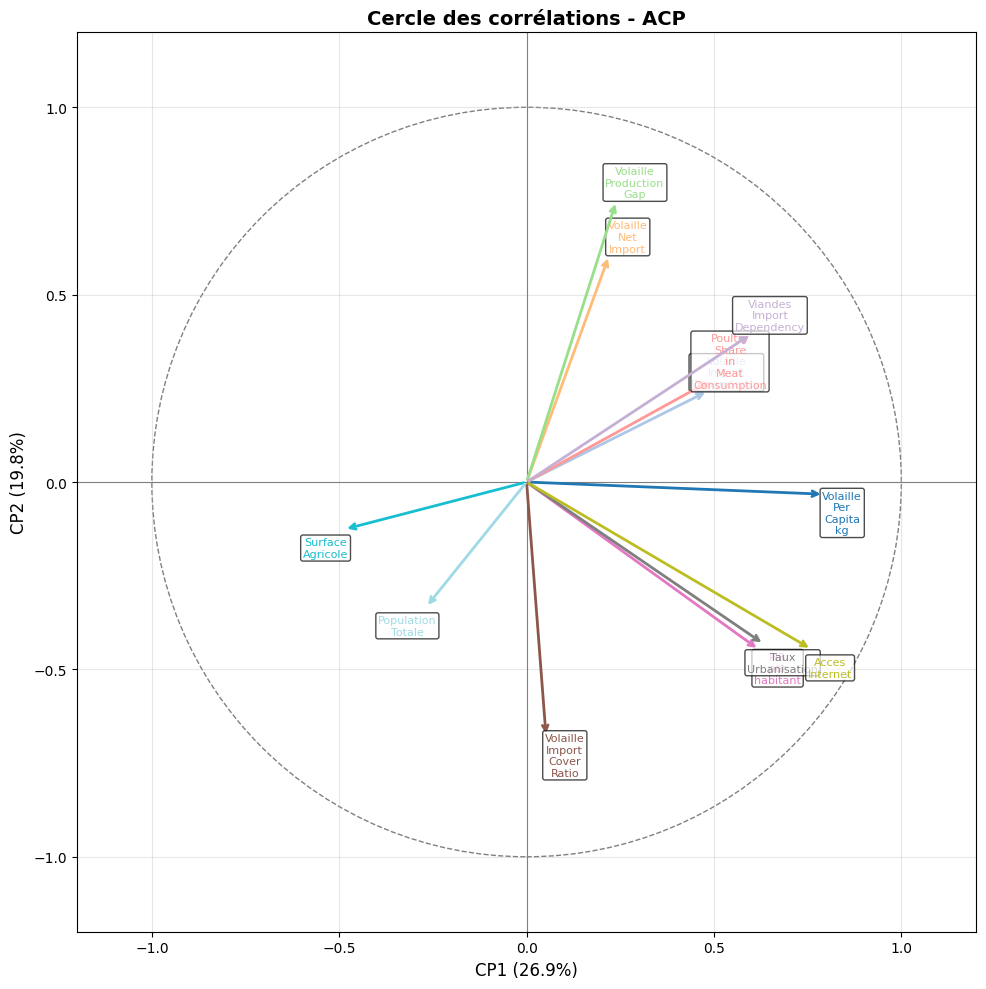

In [9]:
# Coordonnées des variables dans l'espace ACP
# = corrélations entre les variables originales et les composantes
correlations = pca_final.components_.T * np.sqrt(pca_final.explained_variance_)

fig, ax = plt.subplots(figsize=(10, 10))

# Cercle unité
cercle = plt.Circle((0, 0), 1, fill=False, color='gray', linestyle='--', linewidth=1)
ax.add_patch(cercle)

# Flèches et labels
colors = plt.cm.tab20(np.linspace(0, 1, len(vars_acp)))
for i, (var, coord) in enumerate(zip(vars_acp, correlations)):
    ax.annotate('', xy=(coord[0], coord[1]), xytext=(0, 0),
                arrowprops=dict(arrowstyle='->', color=colors[i], lw=2))
    offset_x = 0.05 if coord[0] >= 0 else -0.05
    offset_y = 0.05 if coord[1] >= 0 else -0.05
    ax.text(coord[0] + offset_x, coord[1] + offset_y,
            var.replace('_', '\n'), fontsize=8, color=colors[i],
            ha='center', va='center',
            bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.7))

ax.axhline(0, color='gray', linewidth=0.8, linestyle='-')
ax.axvline(0, color='gray', linewidth=0.8, linestyle='-')
ax.set_xlim(-1.2, 1.2)
ax.set_ylim(-1.2, 1.2)
ax.set_xlabel(f'CP1 ({pca_final.explained_variance_ratio_[0]*100:.1f}%)', fontsize=12)
ax.set_ylabel(f'CP2 ({pca_final.explained_variance_ratio_[1]*100:.1f}%)', fontsize=12)
ax.set_title('Cercle des corrélations - ACP', fontsize=14, fontweight='bold')
ax.set_aspect('equal')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('cercle_correlations.png', dpi=120, bbox_inches='tight')
plt.show()

### Interprétation du cercle des corrélations

**Axe 1 (CP1 - 26,4 %) : développement économique**

L'axe 1 oppose :
- À droite (+) : `Volaille_Per_Capita_kg`, `PIB_par_habitant`, `Taux_Urbanisation`,
  `Acces_Internet` → pays développés, riches et urbains avec une forte consommation
  de volaille par habitant
- À gauche (−) : `Surface_Agricole`, `Population_Totale` → grands pays agricoles
  à forte population rurale et production locale importante

**Axe 2 (CP2 - 20,7 %) : dépendance aux importations de volaille**

L'axe 2 oppose :
- En haut (+) : `Volaille_Import_Dependency`, `Volaille_Net_Import`,
  `Volaille_Production_Gap`, `Viandes_Import_Dependency`,
  `Poultry_Share_in_Meat_Consumption` → pays structurellement importateurs,
  dont la volaille représente la majorité de la consommation de viande
- En bas (−) : `PIB_par_habitant`, `Taux_Urbanisation`, `Acces_Internet`,
  `Volaille_Import_Cover_Ratio` → pays développés autosuffisants en volaille,
  à alimentation carnée diversifiée (bovins, porc, ovins)

**Synthèse :** Un pays situé en haut à droite du plan factoriel cumule les deux profils
favorables pour l'export : riche, urbain ET fortement importateur de volaille.
C'est précisément le quadrant des îles des Caraïbes et des pays du Golfe.

## 6. Projection des individus (nuage 2D)

> **Comment lire la projection des individus ?**
> - Chaque point est un pays
> - Les pays **proches** ont des profils similaires → bons candidats pour être dans le même cluster
> - Les pays **éloignés** ont des profils très différents
> - En combinant avec le cercle des corrélations, on peut interpréter ce qui différencie les groupes


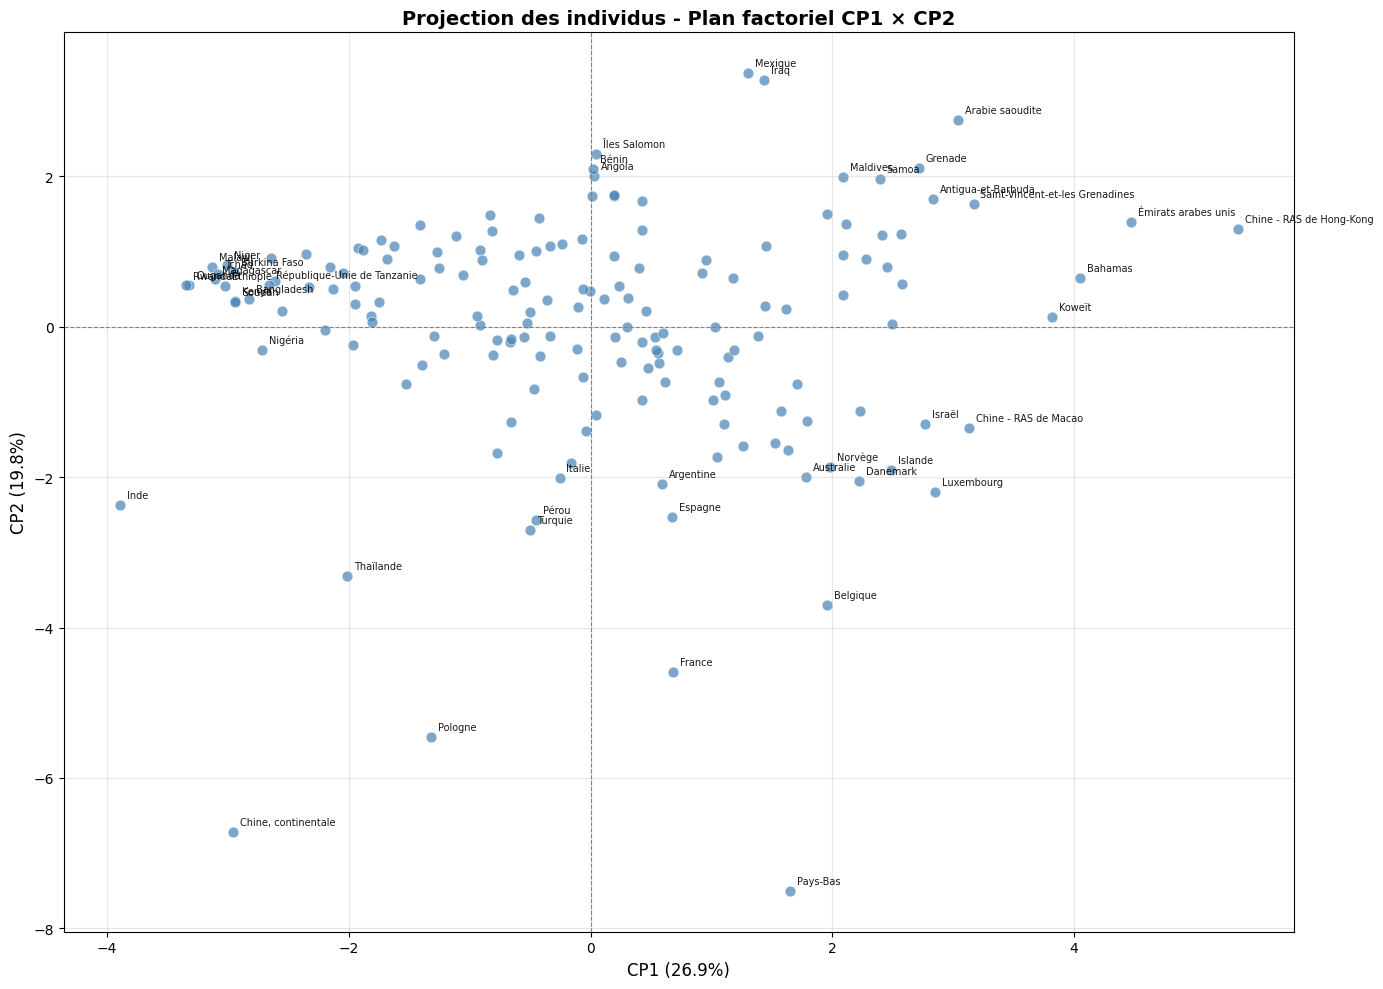

In [10]:
fig, ax = plt.subplots(figsize=(14, 10))

# Scatter des pays
scatter = ax.scatter(X_pca_final[:, 0], X_pca_final[:, 1],
                     alpha=0.7, s=60, color='steelblue', edgecolors='white', linewidth=0.5)

# Labels des pays (seulement les plus extrêmes pour la lisibilité)
seuil = np.percentile(np.abs(X_pca_final[:, 0]), 85)
seuil2 = np.percentile(np.abs(X_pca_final[:, 1]), 85)

for j, pays_nom in enumerate(pays):
    if abs(X_pca_final[j, 0]) > seuil or abs(X_pca_final[j, 1]) > seuil2:
        ax.annotate(pays_nom, (X_pca_final[j, 0], X_pca_final[j, 1]),
                    fontsize=7, alpha=0.9,
                    xytext=(5, 5), textcoords='offset points')

ax.axhline(0, color='gray', linewidth=0.8, linestyle='--')
ax.axvline(0, color='gray', linewidth=0.8, linestyle='--')
ax.set_xlabel(f'CP1 ({pca_final.explained_variance_ratio_[0]*100:.1f}%)', fontsize=12)
ax.set_ylabel(f'CP2 ({pca_final.explained_variance_ratio_[1]*100:.1f}%)', fontsize=12)
ax.set_title('Projection des individus - Plan factoriel CP1 × CP2', fontsize=14, fontweight='bold')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('projection_individus.png', dpi=120, bbox_inches='tight')
plt.show()

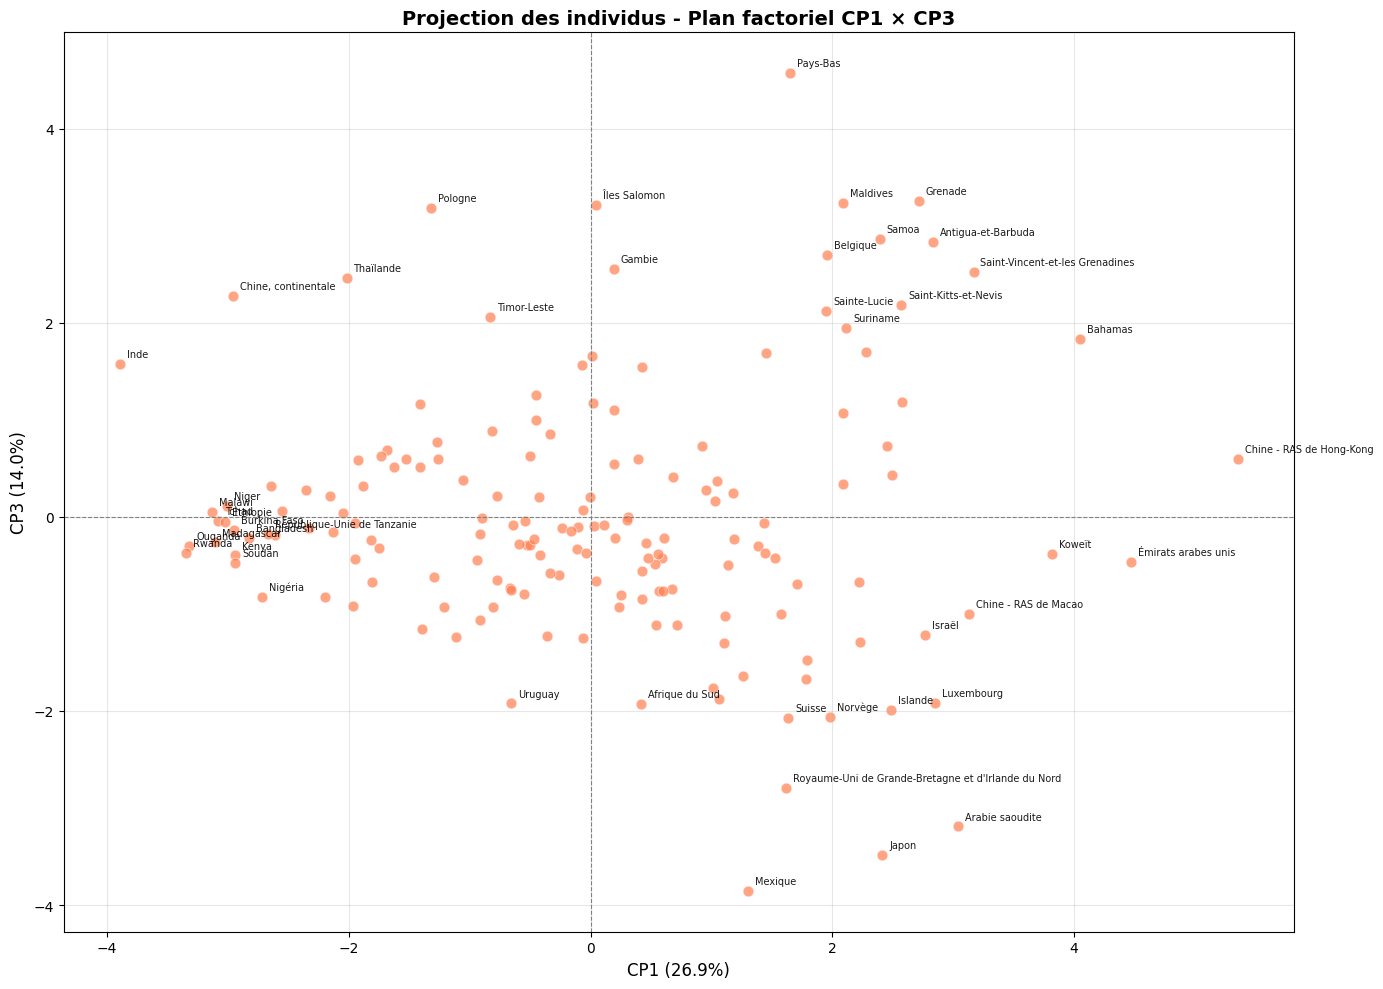

In [11]:
fig, ax = plt.subplots(figsize=(14, 10))

scatter = ax.scatter(X_pca_final[:, 0], X_pca_final[:, 2],
                     alpha=0.7, s=60, color='coral', edgecolors='white', linewidth=0.5)

seuil = np.percentile(np.abs(X_pca_final[:, 0]), 85)
seuil3 = np.percentile(np.abs(X_pca_final[:, 2]), 85)

for j, pays_nom in enumerate(pays):
    if abs(X_pca_final[j, 0]) > seuil or abs(X_pca_final[j, 2]) > seuil3:
        ax.annotate(pays_nom, (X_pca_final[j, 0], X_pca_final[j, 2]),
                    fontsize=7, alpha=0.9,
                    xytext=(5, 5), textcoords='offset points')

ax.axhline(0, color='gray', linewidth=0.8, linestyle='--')
ax.axvline(0, color='gray', linewidth=0.8, linestyle='--')
ax.set_xlabel(f'CP1 ({pca_final.explained_variance_ratio_[0]*100:.1f}%)', fontsize=12)
ax.set_ylabel(f'CP3 ({pca_final.explained_variance_ratio_[2]*100:.1f}%)', fontsize=12)
ax.set_title('Projection des individus - Plan factoriel CP1 × CP3', fontsize=14, fontweight='bold')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('projection_individus_cp1_cp3.png', dpi=120, bbox_inches='tight')
plt.show()

## 7. CAH - Classification Ascendante Hiérarchique

> **Principe de la CAH**
> La CAH regroupe progressivement les pays les plus proches entre eux, en partant
> de chaque pays isolé jusqu'à former un seul groupe. Le résultat est un **dendrogramme**
> qui montre l'ordre des regroupements. On "coupe" le dendrogramme à une hauteur donnée
> pour obtenir un nombre de clusters.


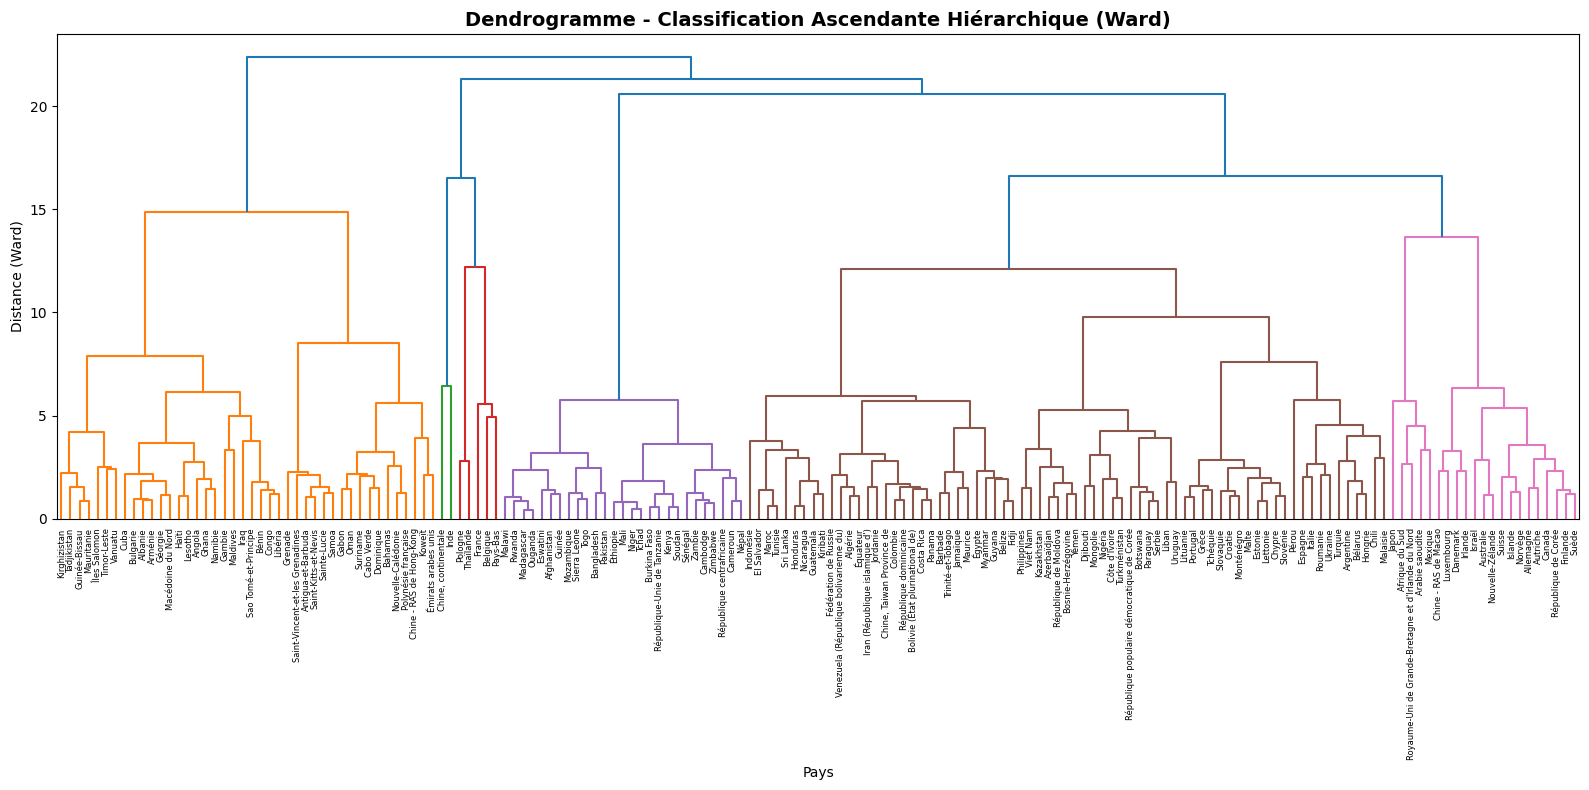

In [12]:
# Calcul de la CAH sur les données standardisées (méthode de Ward)
Z = linkage(X_scaled, method='ward')

# Dendrogramme complet
fig, ax = plt.subplots(figsize=(16, 8))
dendrogram(Z, labels=pays, leaf_rotation=90, leaf_font_size=6, ax=ax,
           color_threshold=0.7*max(Z[:,2]))
ax.set_title('Dendrogramme - Classification Ascendante Hiérarchique (Ward)', fontsize=14, fontweight='bold')
ax.set_xlabel('Pays')
ax.set_ylabel('Distance (Ward)')
plt.tight_layout()
plt.savefig('dendrogramme.png', dpi=120, bbox_inches='tight')
plt.show()

### 7.1 Choix du nombre de clusters pour la CAH

On observe les plus grands sauts de distance dans le dendrogramme pour décider où couper.


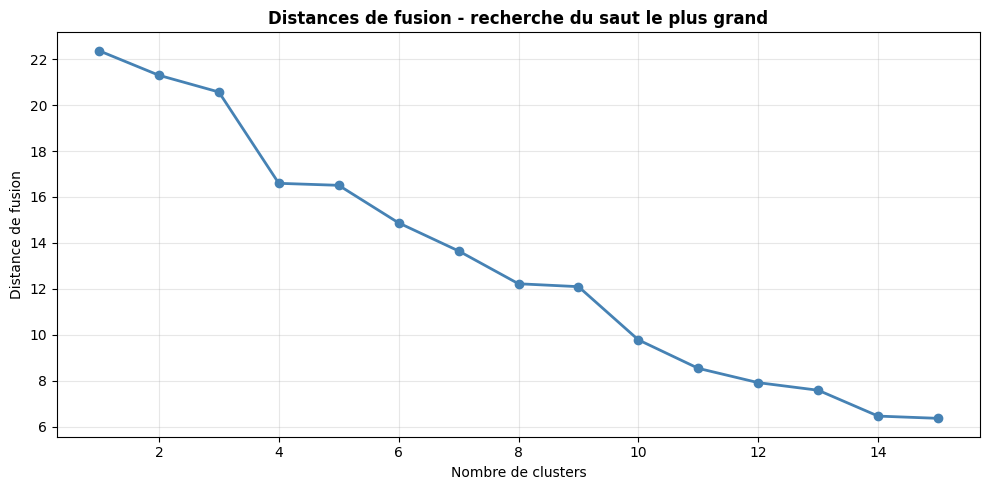

Sauts de distance (plus le saut est grand, plus la coupure est pertinente) :
  14 -> 13 clusters : saut = 0.10
  13 -> 12 clusters : saut = 1.13
  12 -> 11 clusters : saut = 0.33
  11 -> 10 clusters : saut = 0.62
  10 -> 9 clusters : saut = 1.24
  9 -> 8 clusters : saut = 2.32
  8 -> 7 clusters : saut = 0.13
  7 -> 6 clusters : saut = 1.43
  6 -> 5 clusters : saut = 1.22
  5 -> 4 clusters : saut = 1.64
  4 -> 3 clusters : saut = 0.09
  3 -> 2 clusters : saut = 3.98
  2 -> 1 clusters : saut = 0.73
  1 -> 0 clusters : saut = 1.07


In [13]:
# Les 15 dernières fusions et leurs distances
distances = Z[-15:, 2]
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(range(len(distances), 0, -1), distances, 'o-', color='steelblue', linewidth=2)
ax.set_xlabel('Nombre de clusters')
ax.set_ylabel('Distance de fusion')
ax.set_title('Distances de fusion - recherche du saut le plus grand', fontsize=12, fontweight='bold')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Sauts entre fusions successives
sauts = np.diff(distances)
print('Sauts de distance (plus le saut est grand, plus la coupure est pertinente) :')
for i, s in enumerate(sauts):
    print(f'  {len(distances)-i-1} -> {len(distances)-i-2} clusters : saut = {s:.2f}')

In [14]:
# Choix du nombre de clusters pour la CAH (a ajuster selon le graphique)
N_CLUSTERS_CAH = 4

clusters_cah = fcluster(Z, N_CLUSTERS_CAH, criterion='maxclust')
df['Cluster_CAH'] = clusters_cah

print(f'Répartition des {N_CLUSTERS_CAH} clusters (CAH) :')
print(df['Cluster_CAH'].value_counts().sort_index())

Répartition des 4 clusters (CAH) :
Cluster_CAH
1    42
2     7
3    27
4    92
Name: count, dtype: int64


### 7.2 Description analytique des clusters CAH

On décrit les 4 clusters CAH immédiatement après leur création, de la même façon qu'on le fera pour K-means : heatmap des profils moyens, boxplots et profiling des pays représentatifs.


Données utilisées pour le clustering : X_scaled
Moyenne (doit être ≈ 0) : 0.0000
Écart-type (doit être ≈ 1) : 1.0000


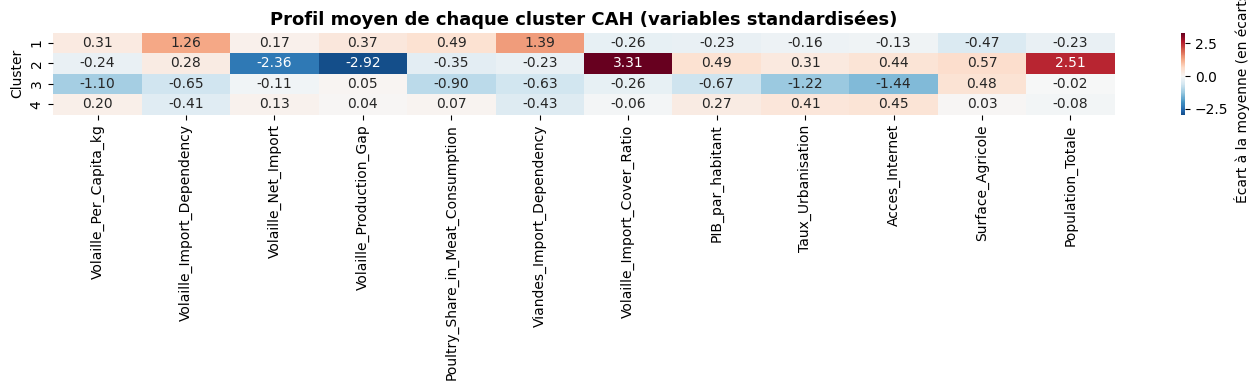

In [15]:
# Vérification : les données sont bien standardisées avant toute description
print(f'Données utilisées pour le clustering : X_scaled')
print(f'Moyenne (doit être ≈ 0) : {X_scaled.mean():.4f}')
print(f'Écart-type (doit être ≈ 1) : {X_scaled.std():.4f}')

# Heatmap des profils moyens CAH
df_scaled_cah = pd.DataFrame(X_scaled, columns=vars_acp)
df_scaled_cah['Cluster'] = df['Cluster_CAH'].values

moyennes_cah = df_scaled_cah.groupby('Cluster')[vars_acp].mean()

fig, ax = plt.subplots(figsize=(14, max(4, N_CLUSTERS_CAH)))
sns.heatmap(moyennes_cah, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            ax=ax, cbar_kws={'label':'Écart à la moyenne (en écarts-types)'})
ax.set_title('Profil moyen de chaque cluster CAH (variables standardisées)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('heatmap_cah.png', dpi=120, bbox_inches='tight')
plt.show()

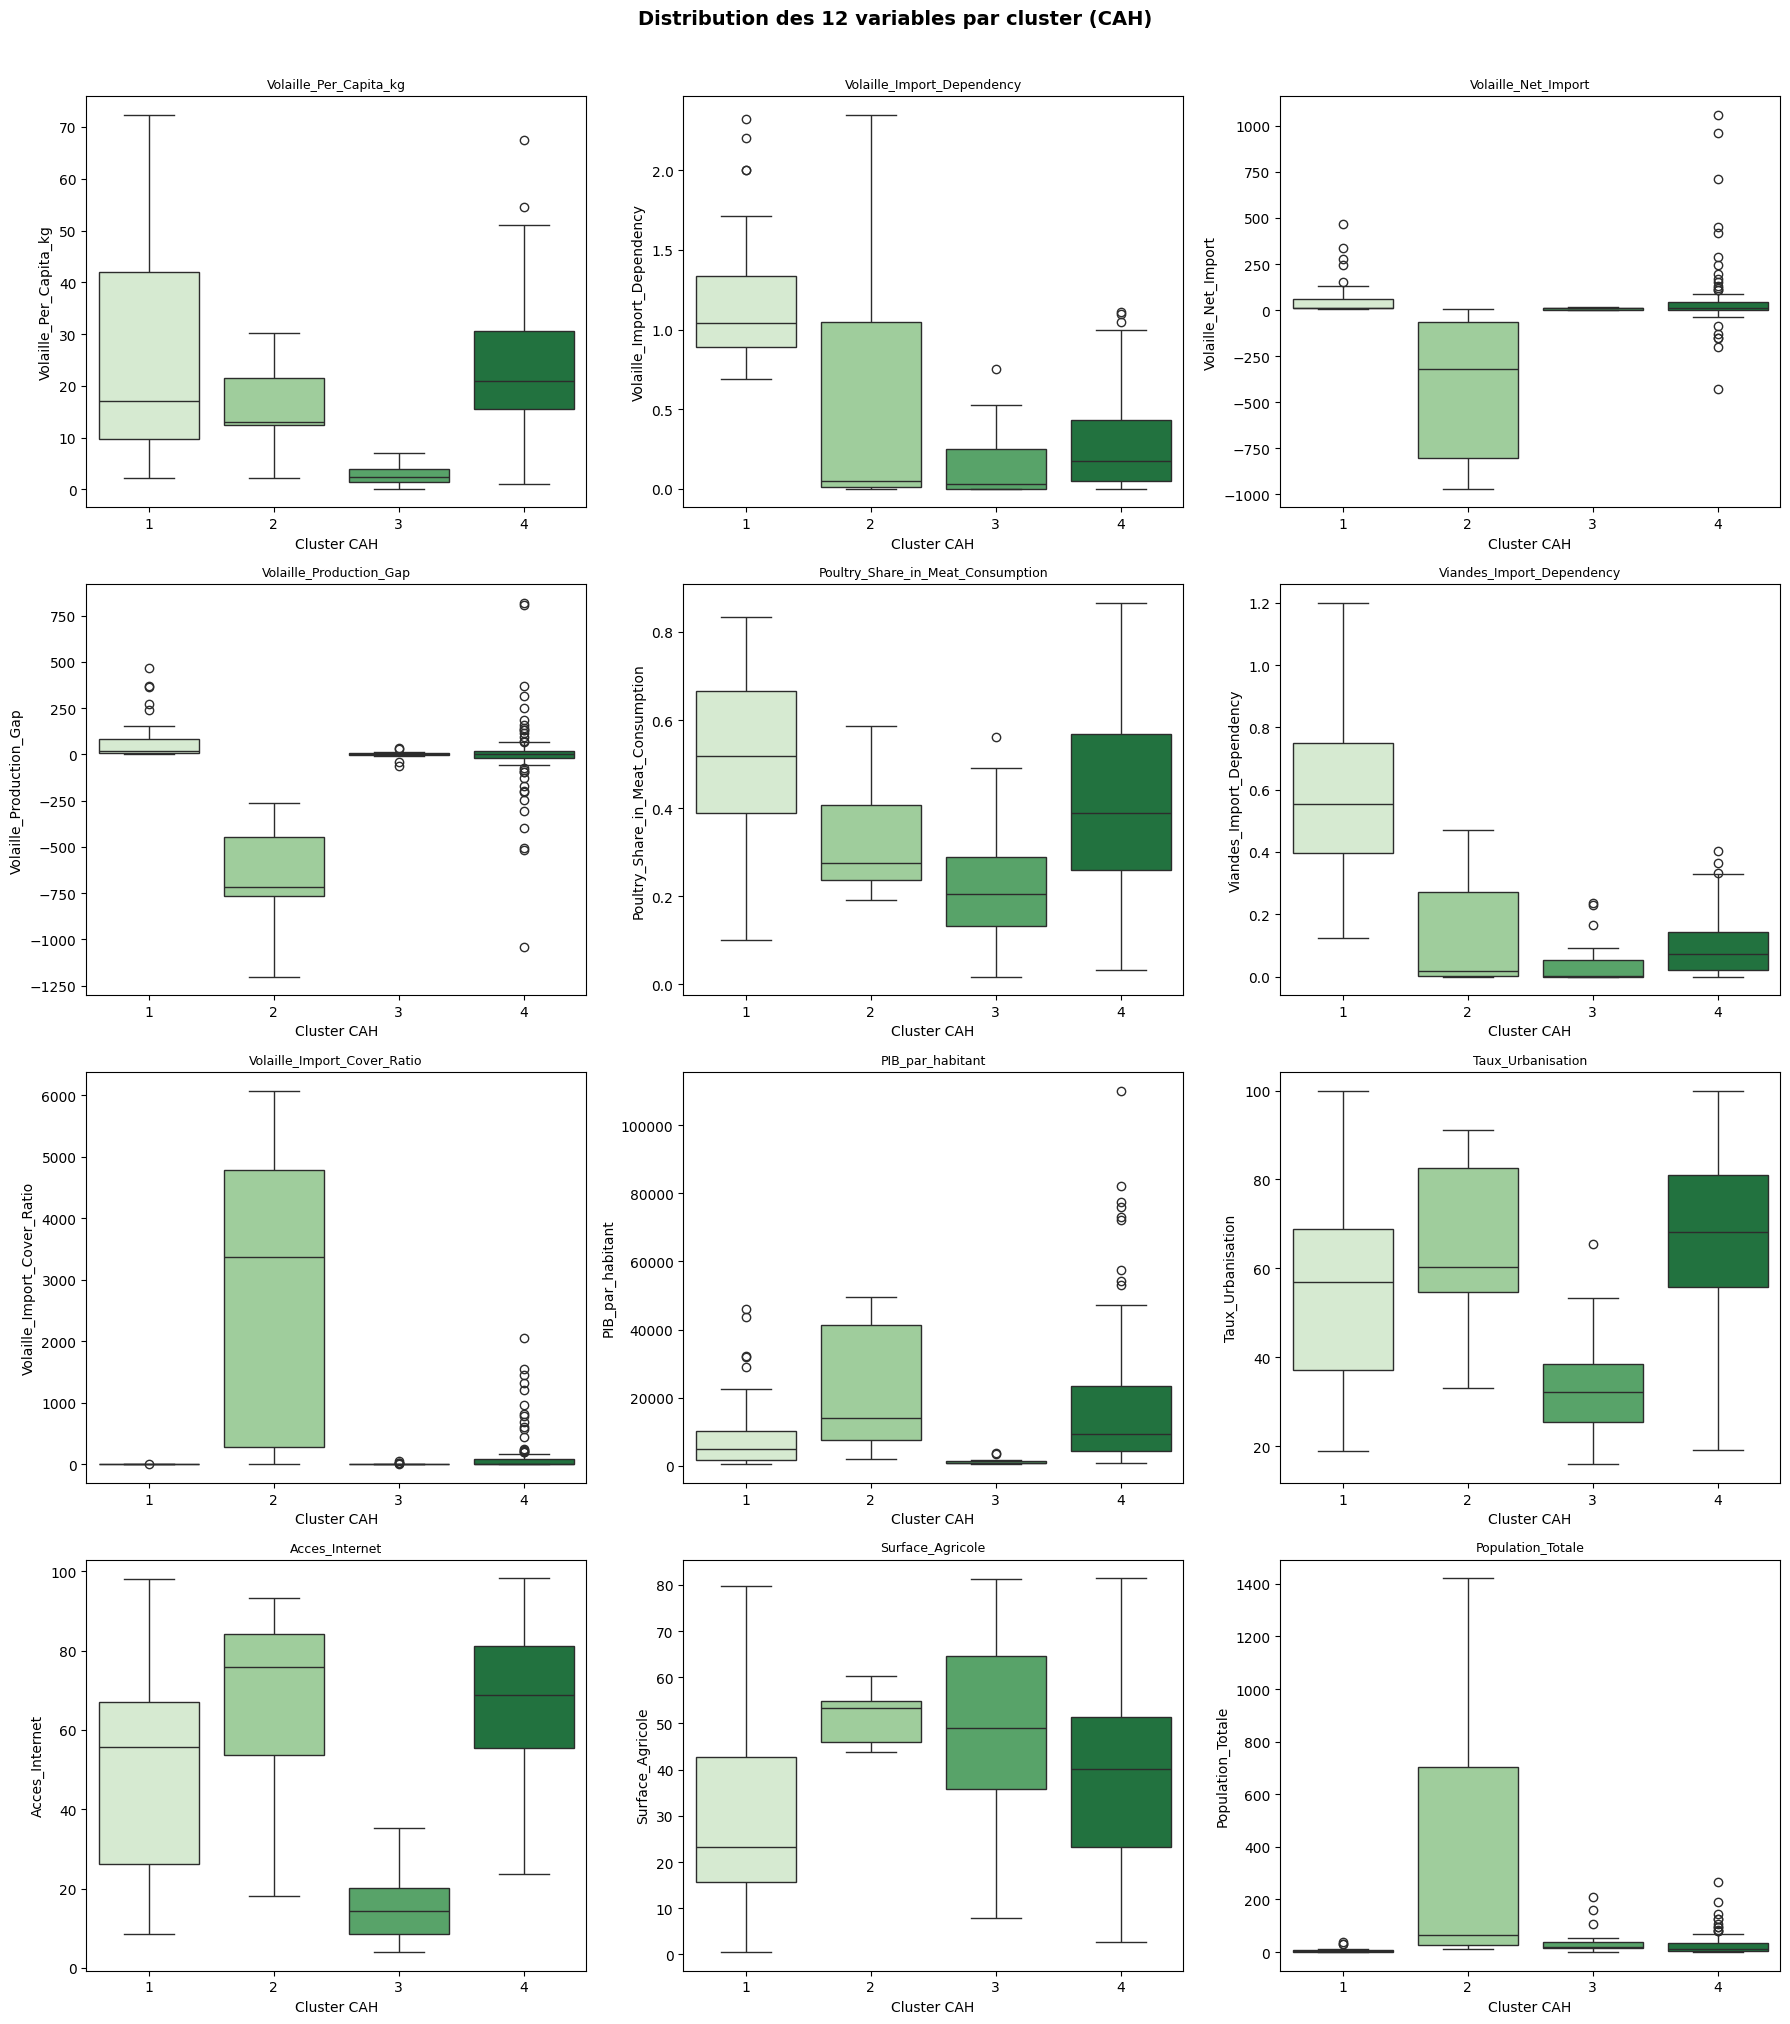

In [16]:
# Boxplots CAH - 12 variables
fig, axes = plt.subplots(4, 3, figsize=(18, 20))
axes = axes.flatten()

for i, var in enumerate(vars_acp):
    data_plot = df[[var, 'Cluster_CAH']].copy()
    sns.boxplot(data=data_plot, x='Cluster_CAH', y=var, ax=axes[i], palette='Greens')
    axes[i].set_title(var, fontsize=9)
    axes[i].set_xlabel('Cluster CAH')

plt.suptitle('Distribution des 12 variables par cluster (CAH)', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('boxplots_cah.png', dpi=120, bbox_inches='tight')
plt.show()

In [17]:
# Profiling des pays par cluster CAH
print('Profiling des clusters CAH\n')
for cluster_id in sorted(df['Cluster_CAH'].unique()):
    sous_df = df[df['Cluster_CAH'] == cluster_id]
    print(f'{"="*70}')
    print(f'CLUSTER CAH {cluster_id}  -  {len(sous_df)} pays')
    print(f'{"="*70}')
    print(f'Pays : {", ".join(sous_df["Zone"].head(12).tolist())}')
    print(f'Moyennes des variables clés :')
    for var in vars_acp:
        moy = sous_df[var].mean()
        moy_g = df[var].mean()
        ecart = '▲' if moy > moy_g else '▼'
        print(f'  {ecart} {var:40s} : {moy:>10.2f}  (global : {moy_g:.2f})')
    print()

Profiling des clusters CAH

CLUSTER CAH 1  -  42 pays
Pays : Albanie, Angola, Antigua-et-Barbuda, Arménie, Bahamas, Bulgarie, Bénin, Cabo Verde, Chine - RAS de Hong-Kong, Congo, Cuba, Dominique
Moyennes des variables clés :
  ▲ Volaille_Per_Capita_kg                   :      24.75  (global : 20.00)
  ▲ Volaille_Import_Dependency               :       1.17  (global : 0.49)
  ▲ Volaille_Net_Import                      :      61.40  (global : 28.52)
  ▲ Volaille_Production_Gap                  :      69.60  (global : -12.52)
  ▲ Poultry_Share_in_Meat_Consumption        :       0.51  (global : 0.41)
  ▲ Viandes_Import_Dependency                :       0.58  (global : 0.21)
  ▼ Volaille_Import_Cover_Ratio              :       1.53  (global : 206.93)
  ▼ PIB_par_habitant                         :    9550.92  (global : 13987.74)
  ▼ Taux_Urbanisation                        :      55.45  (global : 58.90)
  ▼ Acces_Internet                           :      50.83  (global : 54.35)
  ▼ Surface_Ag

### 7.3 Synthèse des profils CAH

| Cluster | Nb pays | Profil | Pays types | Recommandation export |
|---|---|---|---|---|
| **1** | 42 | Importateurs nets de volaille - forte dépendance aux imports (1,17 vs 0,49), bonne consommation par habitant (24,75 kg), petits pays peu agricoles | Antigua-et-Barbuda, Bahamas, Bénin, Cabo Verde, Hong-Kong, Congo, Cuba | **Cible prioritaire** - structurellement dépendants des imports, appétit pour la volaille déjà installé |
| **2** | 7 | Géants producteurs/exportateurs - production massivement excédentaire, Net_Import très négatif (-430), inclut les concurrents directs français | Belgique, France, Pays-Bas, Chine continentale, Inde, Pologne, Thaïlande | **À exclure** - concurrents à l'export, pas des marchés cibles |
| **3** | 27 | Pays pauvres à très faible consommation (2,91 kg) - PIB très bas (1 167 $/hab), très peu urbains (33 %), quasi-autosuffisants par défaut faute de moyens | Afghanistan, Bangladesh, Burkina Faso, Kenya, Mali, Mozambique | **Non prioritaire** - pouvoir d'achat insuffisant pour un poulet bio premium |
| **4** | 92 | Pays développés autosuffisants - consommation correcte (23 kg), faible dépendance aux imports (0,28), PIB élevé, bonne urbanisation | Afrique du Sud, Allemagne, Arabie saoudite, Argentine, Australie | **Cible secondaire** - marchés matures, production locale concurrente mais pouvoir d'achat fort |

> **Conclusion CAH :** Le Cluster 1 est la cible prioritaire - il concentre les pays dont la dépendance structurelle aux imports est la plus forte, avec une consommation de volaille déjà significative. Le Cluster 4 représente une cible secondaire à travailler sur la différenciation (bio, qualité). Les Clusters 2 et 3 sont à écarter pour des raisons opposées : trop compétitifs ou trop peu solvables.

## 8. K-means - Recherche du nombre optimal de clusters

> **Principe du K-means**
> K-means partitionne les pays en K groupes en minimisant la distance entre chaque
> pays et le centre (centroïde) de son cluster. Contrairement à la CAH, il faut
> fixer K **à l'avance** - on teste plusieurs valeurs et on choisit la meilleure
> selon des métriques objectives.

### 8.1 Méthode du coude (inertie) + Coefficient de silhouette + Indice de Davies-Bouldin


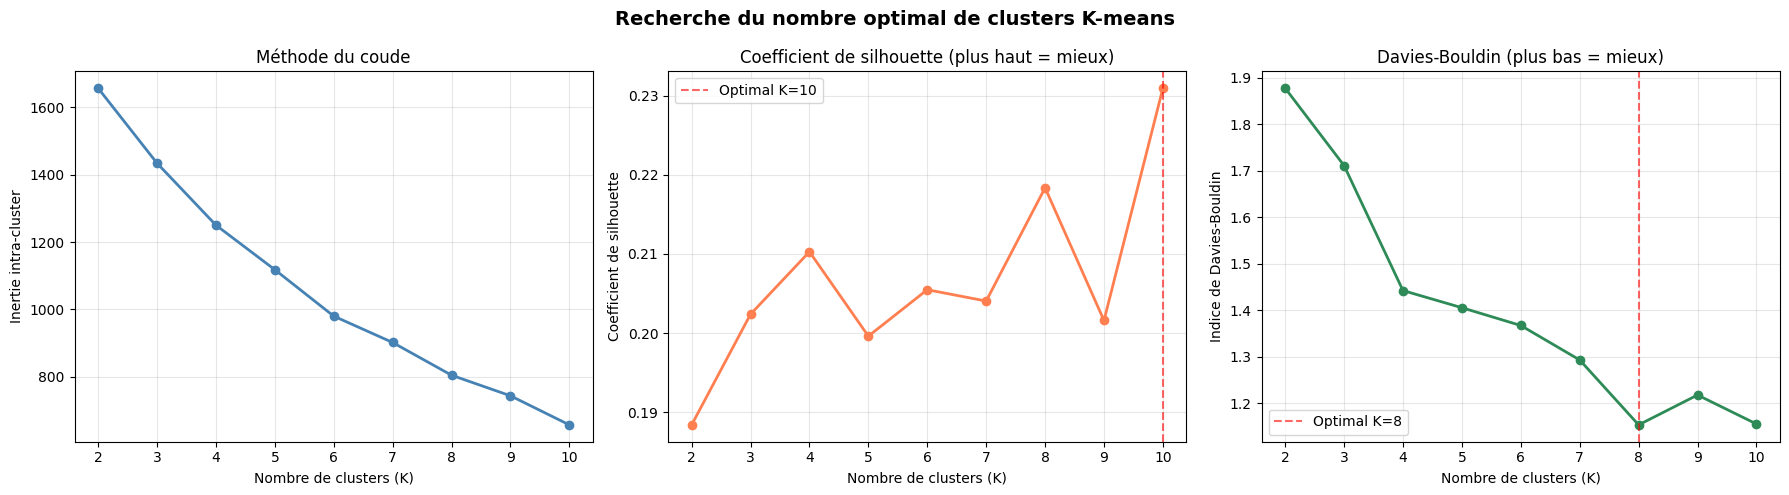

K optimal selon silhouette      : 10 (score = 0.231)
K optimal selon Davies-Bouldin  : 8 (score = 1.154)


In [18]:
from sklearn.metrics import davies_bouldin_score

K_range = range(2, 11)
inerties = []
silhouettes = []
davies_bouldin = []

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    inerties.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels))
    davies_bouldin.append(davies_bouldin_score(X_scaled, labels))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Coude (inertie)
axes[0].plot(K_range, inerties, 'o-', color='steelblue', linewidth=2)
axes[0].set_xlabel('Nombre de clusters (K)')
axes[0].set_ylabel('Inertie intra-cluster')
axes[0].set_title('Méthode du coude')
axes[0].grid(True, alpha=0.3)

# Silhouette (plus haut = mieux)
axes[1].plot(K_range, silhouettes, 'o-', color='coral', linewidth=2)
best_k_sil = list(K_range)[np.argmax(silhouettes)]
axes[1].axvline(best_k_sil, color='red', linestyle='--', alpha=0.6, label=f'Optimal K={best_k_sil}')
axes[1].set_xlabel('Nombre de clusters (K)')
axes[1].set_ylabel('Coefficient de silhouette')
axes[1].set_title('Coefficient de silhouette (plus haut = mieux)')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# Davies-Bouldin (plus bas = mieux)
axes[2].plot(K_range, davies_bouldin, 'o-', color='seagreen', linewidth=2)
best_k_db = list(K_range)[np.argmin(davies_bouldin)]
axes[2].axvline(best_k_db, color='red', linestyle='--', alpha=0.6, label=f'Optimal K={best_k_db}')
axes[2].set_xlabel('Nombre de clusters (K)')
axes[2].set_ylabel('Indice de Davies-Bouldin')
axes[2].set_title('Davies-Bouldin (plus bas = mieux)')
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.suptitle('Recherche du nombre optimal de clusters K-means', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('choix_k.png', dpi=120, bbox_inches='tight')
plt.show()

print(f'K optimal selon silhouette      : {best_k_sil} (score = {max(silhouettes):.3f})')
print(f'K optimal selon Davies-Bouldin  : {best_k_db} (score = {min(davies_bouldin):.3f})')

### 8.2 Choix final de K et entraînement du modèle

Le coude de l'inertie se situe autour de K=4. Le coefficient de silhouette atteint son maximum absolu à K=10 (0,231) mais présente un pic local à K=4 (0,210) et K=8 (0,218). L'indice de Davies-Bouldin est minimal à K=8 (1,154). Les scores de silhouette restent globalement faibles (< 0,25) quel que soit K, ce qui reflète une structure de clusters peu marquée - attendu pour des données socio-économiques continues. On retient K=4 : ce choix est cohérent avec le coude, comparable au nombre de clusters obtenu en CAH (facilite la comparaison), et offre une segmentation interprétable et actionnable pour la stratégie d'export, alors que K=8 ou K=10 fragmenteraient excessivement l'analyse pour la présentation COMEX.


In [19]:
# Comparaison des 3 valeurs candidates
from sklearn.metrics import davies_bouldin_score, silhouette_score

candidats = [4, 8, 10]
resultats = []

print('Comparaison K = 4, K = 8, K = 10')
print(f'{"K":>4} | {"Inertie":>10} | {"Silhouette":>12} | {"Davies-Bouldin":>16} | {"Répartition"}')
print('-' * 80)

for k in candidats:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertie = km.inertia_
    sil = silhouette_score(X_scaled, labels)
    db = davies_bouldin_score(X_scaled, labels)
    repartition = {int(k): int(v) for k, v in zip(*np.unique(labels, return_counts=True))}
    print(f'{k:>4} | {inertie:>10.1f} | {sil:>12.3f} | {db:>16.3f} | {repartition}')
    resultats.append({'K': k, 'labels': labels, 'inertie': inertie, 'silhouette': sil, 'db': db})

# Entraînement final avec K retenu
N_CLUSTERS_KMEANS = 4
kmeans_final = KMeans(n_clusters=N_CLUSTERS_KMEANS, random_state=42, n_init=10)
df['Cluster_KMeans'] = kmeans_final.fit_predict(X_scaled)

# Distance au centroïde (variable supplémentaire recommandée par le mentor)
distances_centroide = kmeans_final.transform(X_scaled).min(axis=1)
df['Distance_Centroide'] = distances_centroide.round(3)

print(f'\nK retenu : {N_CLUSTERS_KMEANS}')
print(f'Score de silhouette final : {silhouette_score(X_scaled, df["Cluster_KMeans"]):.3f}')
print(f'\nRépartition des clusters :')
print(df['Cluster_KMeans'].value_counts().sort_index())
print(f'\nDistance au centroïde (stats) :')
print(df.groupby("Cluster_KMeans")["Distance_Centroide"].describe().round(2))

Comparaison K = 4, K = 8, K = 10
   K |    Inertie |   Silhouette |   Davies-Bouldin | Répartition
--------------------------------------------------------------------------------
   4 |     1250.3 |        0.210 |            1.442 | {0: 30, 1: 62, 2: 72, 3: 4}
   8 |      804.9 |        0.218 |            1.154 | {0: 21, 1: 59, 2: 42, 3: 32, 4: 2, 5: 3, 6: 5, 7: 4}
  10 |      657.5 |        0.231 |            1.155 | {0: 19, 1: 33, 2: 17, 3: 39, 4: 2, 5: 3, 6: 30, 7: 16, 8: 5, 9: 4}

K retenu : 4
Score de silhouette final : 0.210

Répartition des clusters :
Cluster_KMeans
0    30
1    62
2    72
3     4
Name: count, dtype: int64

Distance au centroïde (stats) :
                count  mean   std   min   25%   50%   75%   max
Cluster_KMeans                                                 
0                30.0  2.75  1.12  1.36  1.94  2.58  3.12  6.21
1                62.0  2.47  1.14  0.97  1.82  2.18  3.04  7.39
2                72.0  2.18  1.07  0.82  1.71  2.01  2.31  9.02
3       

## 10. Description analytique des clusters (K-means)

### 10.1 Heatmap des moyennes par cluster

Pour chaque cluster, on calcule la moyenne de chaque variable, standardisée
pour permettre la comparaison (au-dessus de 0 = supérieur à la moyenne générale).


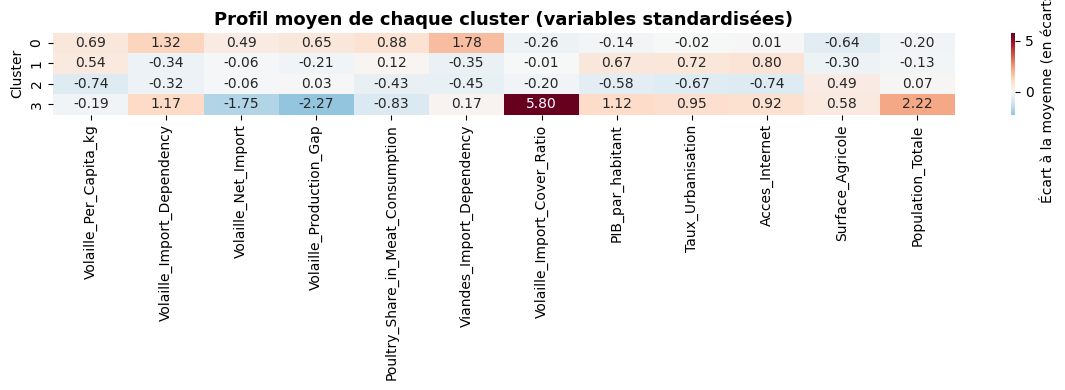

In [20]:
# Moyennes par cluster (variables standardisées)
df_scaled_with_cluster = pd.DataFrame(X_scaled, columns=vars_acp)
df_scaled_with_cluster['Cluster'] = df['Cluster_KMeans'].values

moyennes_cluster = df_scaled_with_cluster.groupby('Cluster')[vars_acp].mean()

fig, ax = plt.subplots(figsize=(12, max(4, N_CLUSTERS_KMEANS)))
sns.heatmap(moyennes_cluster, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            ax=ax, cbar_kws={'label':'Écart à la moyenne (en écarts-types)'})
ax.set_title('Profil moyen de chaque cluster (variables standardisées)', fontsize=13, fontweight='bold')
ax.set_xlabel('')
ax.set_ylabel('Cluster')
plt.tight_layout()
plt.savefig('heatmap_clusters.png', dpi=120, bbox_inches='tight')
plt.show()

### 10.2 Boxplots par cluster

Pour les variables les plus discriminantes, on visualise la distribution complète par cluster
(pas seulement la moyenne).


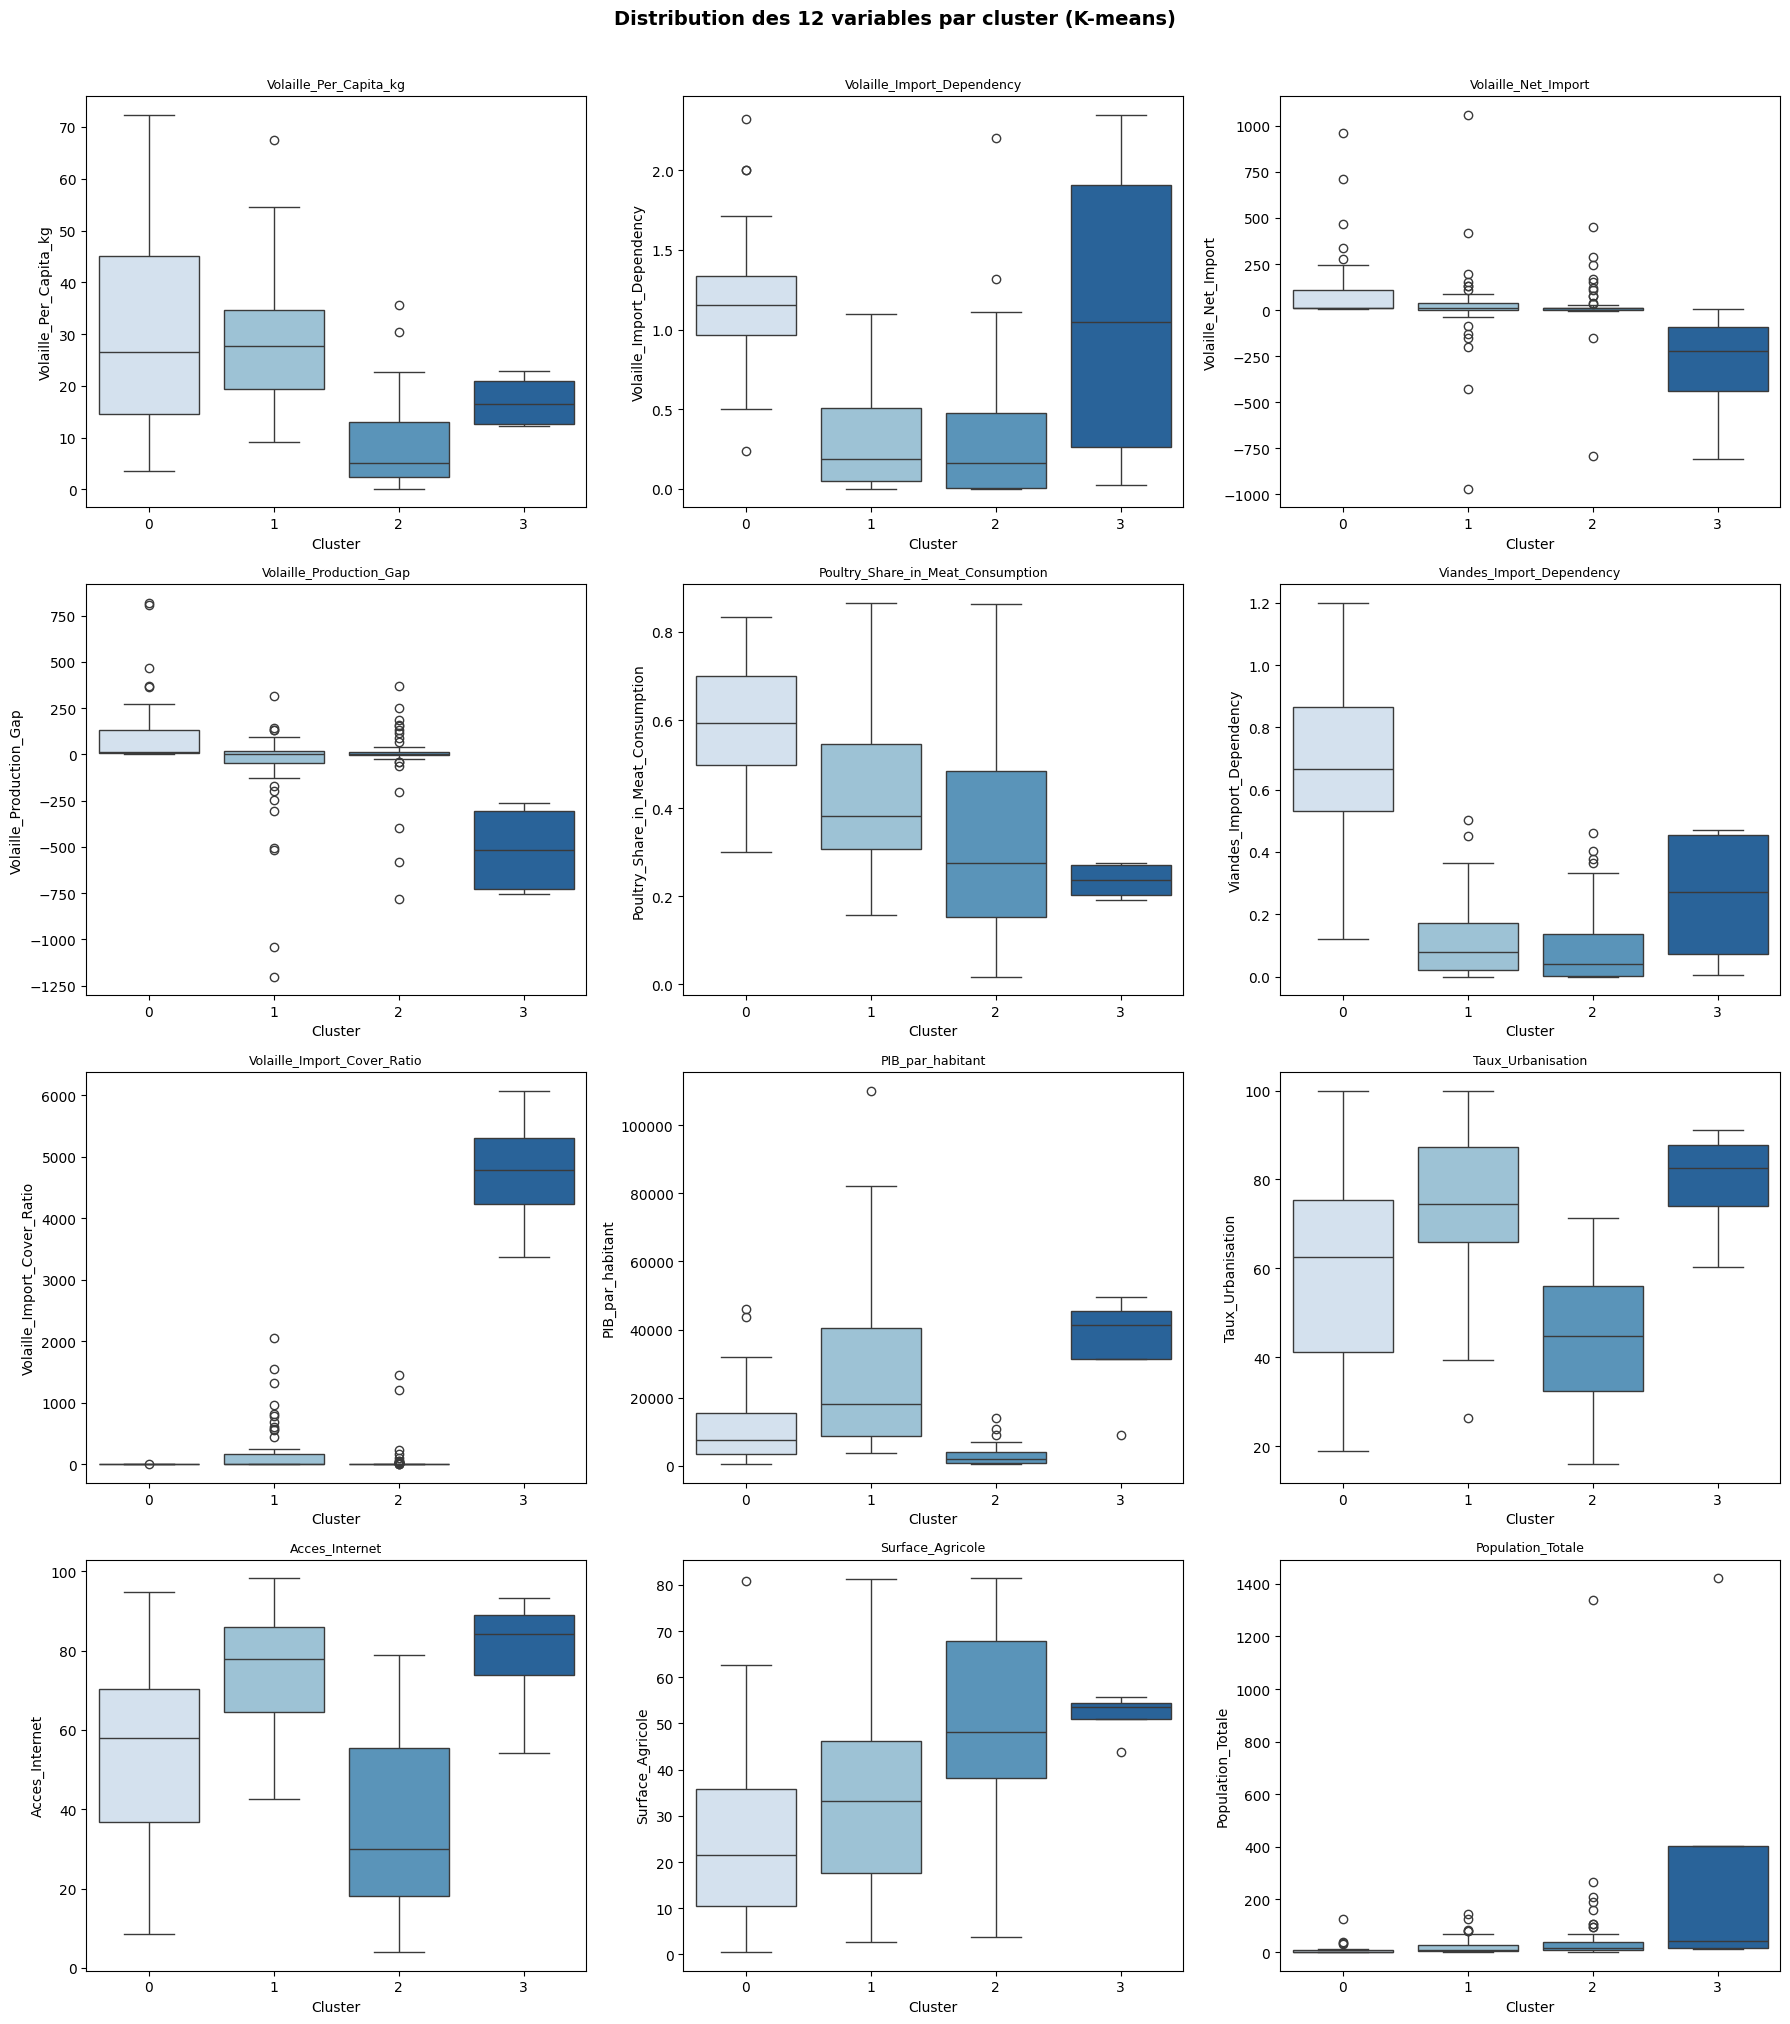

In [21]:
fig, axes = plt.subplots(4, 3, figsize=(18, 20))
axes = axes.flatten()

for i, var in enumerate(vars_acp):
    data_plot = df[[var, 'Cluster_KMeans']].copy()
    sns.boxplot(data=data_plot, x='Cluster_KMeans', y=var, ax=axes[i], palette='Blues')
    axes[i].set_title(var, fontsize=9)
    axes[i].set_xlabel('Cluster')

plt.suptitle('Distribution des 12 variables par cluster (K-means)', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('boxplots_clusters.png', dpi=120, bbox_inches='tight')
plt.show()

### 10.3 Représentation des clusters dans le plan principal de l'ACP

On affiche les clusters K-means directement sur le nuage des individus (CP1 × CP2).


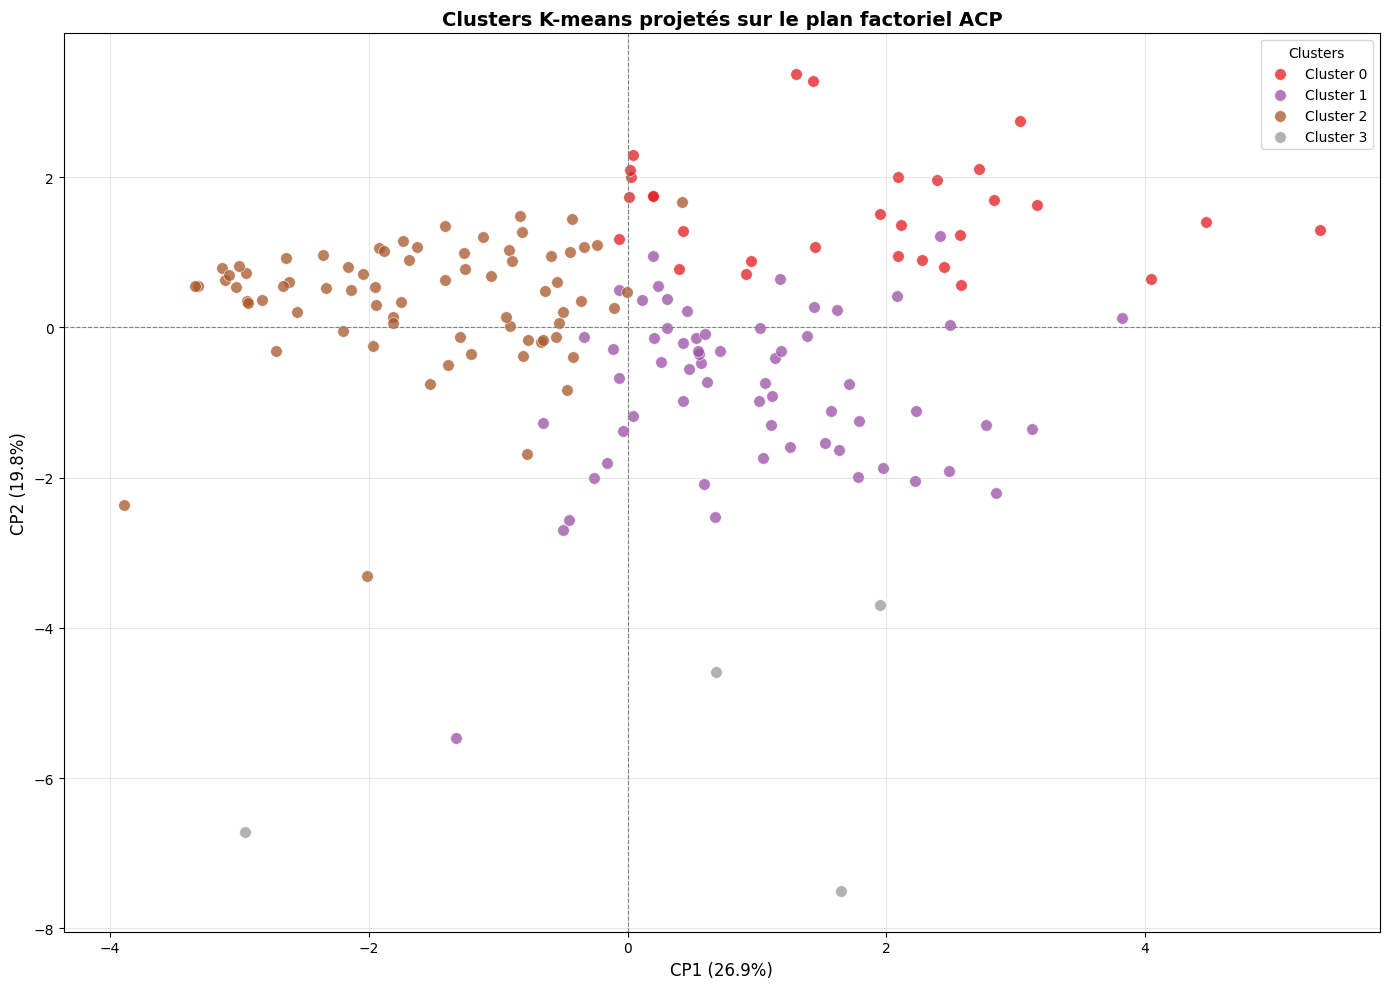

In [22]:
fig, ax = plt.subplots(figsize=(14, 10))

colors_clusters = plt.cm.Set1(np.linspace(0, 1, N_CLUSTERS_KMEANS))

for cluster_id in range(N_CLUSTERS_KMEANS):
    mask = df['Cluster_KMeans'] == cluster_id
    ax.scatter(X_pca_final[mask, 0], X_pca_final[mask, 1],
               color=colors_clusters[cluster_id], label=f'Cluster {cluster_id}',
               alpha=0.75, s=70, edgecolors='white', linewidth=0.5)

ax.axhline(0, color='gray', linewidth=0.8, linestyle='--')
ax.axvline(0, color='gray', linewidth=0.8, linestyle='--')
ax.set_xlabel(f'CP1 ({pca_final.explained_variance_ratio_[0]*100:.1f}%)', fontsize=12)
ax.set_ylabel(f'CP2 ({pca_final.explained_variance_ratio_[1]*100:.1f}%)', fontsize=12)
ax.set_title('Clusters K-means projetés sur le plan factoriel ACP', fontsize=14, fontweight='bold')
ax.legend(title='Clusters', loc='best')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('clusters_acp.png', dpi=120, bbox_inches='tight')
plt.show()

## 11. Profiling métier des clusters

Pour chaque cluster, on identifie les pays représentatifs et on rédige une interprétation
business orientée vers la décision d'export pour La Poule qui Chante.


In [23]:
for cluster_id in range(N_CLUSTERS_KMEANS):
    sous_df = df[df['Cluster_KMeans'] == cluster_id]
    print(f'\n{"="*70}')
    print(f'CLUSTER {cluster_id}  -  {len(sous_df)} pays')
    print(f'{"="*70}')
    print(f'Pays (échantillon) : {", ".join(sous_df["Zone"].head(10).tolist())}')
    print(f'\nMoyennes des variables clés :')
    for var in vars_acp:
        moy = sous_df[var].mean()
        moy_globale = df[var].mean()
        ecart = '▲' if moy > moy_globale else '▼'
        print(f'  {ecart} {var:40s} : {moy:>10.2f}  (global : {moy_globale:.2f})')


CLUSTER 0  -  30 pays
Pays (échantillon) : Angola, Antigua-et-Barbuda, Arabie saoudite, Bahamas, Bénin, Cabo Verde, Chine - RAS de Hong-Kong, Congo, Cuba, Dominique

Moyennes des variables clés :
  ▲ Volaille_Per_Capita_kg                   :      30.70  (global : 20.00)
  ▲ Volaille_Import_Dependency               :       1.20  (global : 0.49)
  ▲ Volaille_Net_Import                      :     123.90  (global : 28.52)
  ▲ Volaille_Production_Gap                  :     131.53  (global : -12.52)
  ▲ Poultry_Share_in_Meat_Consumption        :       0.59  (global : 0.41)
  ▲ Viandes_Import_Dependency                :       0.69  (global : 0.21)
  ▼ Volaille_Import_Cover_Ratio              :       1.48  (global : 206.93)
  ▼ PIB_par_habitant                         :   11346.90  (global : 13987.74)
  ▼ Taux_Urbanisation                        :      58.41  (global : 58.90)
  ▲ Acces_Internet                           :      54.59  (global : 54.35)
  ▼ Surface_Agricole                     

In [24]:
# Distance au centroïde - aide à la priorisation des pays cibles
print("=== PAYS CIBLES PRIORITAIRES (Cluster 0) classés par fiabilité ===\n")

cluster_cible = df[df['Cluster_KMeans'] == 0][['Zone', 'Cluster_KMeans', 'Distance_Centroide',
                                                'Volaille_Per_Capita_kg', 'Volaille_Import_Dependency',
                                                'PIB_par_habitant']].copy()

cluster_cible = cluster_cible.sort_values('Distance_Centroide')

print("Pays les plus représentatifs du cluster (cibles les plus fiables) :")
print(cluster_cible.head(10).to_string(index=False))

print("\nPays en bordure de cluster (à analyser individuellement) :")
print(cluster_cible.tail(5).to_string(index=False))

=== PAYS CIBLES PRIORITAIRES (Cluster 0) classés par fiabilité ===

Pays les plus représentatifs du cluster (cibles les plus fiables) :
                Zone  Cluster_KMeans  Distance_Centroide  Volaille_Per_Capita_kg  Volaille_Import_Dependency  PIB_par_habitant
           Dominique               0               1.359                   35.19                      1.3333       8224.648966
          Cabo Verde               0               1.426                   17.62                      1.3333       3893.095714
            Suriname               0               1.772                   31.06                      1.0000       6049.521286
               Gabon               0               1.812                   29.33                      1.2459       6921.733731
   Macédoine du Nord               0               1.855                   19.73                      0.9756       5955.297386
 Polynésie française               0               1.876                   47.40                      

### 11.1 Synthèse des profils

| Cluster | Profil | Pays types | Recommandation La Poule qui Chante |
|---|---|---|---|
| **0** (30 pays) | Forte dépendance aux imports de volaille, bonne consommation par habitant, PIB modéré | Arabie saoudite, Bahamas, Bénin, Cabo Verde, Hong-Kong, Congo, Cuba | **Cible prioritaire** - forte dépendance import (1,20 vs 0,49 en moyenne) et appétit pour la volaille déjà installé |
| **1** (62 pays) | Pays développés autosuffisants, forte consommation, faible dépendance aux imports | Allemagne, Argentine, Australie, Autriche, Canada | **Cible secondaire** - marché mature mais déjà bien approvisionné localement, peu de place pour un nouvel entrant |
| **2** (72 pays) | Pays en développement, faible consommation, faible PIB, faible urbanisation | Afghanistan, Algérie, Bangladesh, Burkina Faso | **Potentiel à long terme** - demande actuelle limitée par le pouvoir d'achat, à surveiller pour une stratégie différée |
| **3** (4 pays) | Très forte dépendance import malgré richesse élevée, profil atypique | Belgique, Chine continentale, France, Pays-Bas | **À analyser au cas par cas** - cluster très restreint mêlant hubs agro-industriels européens et marché chinois ; nécessite une lecture individuelle plutôt qu'une approche groupée |

> **Conclusion :** Le Cluster 0 constitue la cible prioritaire pour La Poule qui Chante - il combine une dépendance structurelle aux importations de volaille et un niveau de consommation déjà significatif, contrairement au Cluster 2 où la demande reste freinée par le pouvoir d'achat.


## 9. Comparaison CAH vs K-means

On vérifie si les deux méthodes produisent des regroupements similaires via un tableau croisé.


Tableau croisé CAH x K-means :
K-means   0   1   2  3
CAH                   
1        28   3  11  0
2         0   1   2  4
3         0   0  27  0
4         2  58  32  0


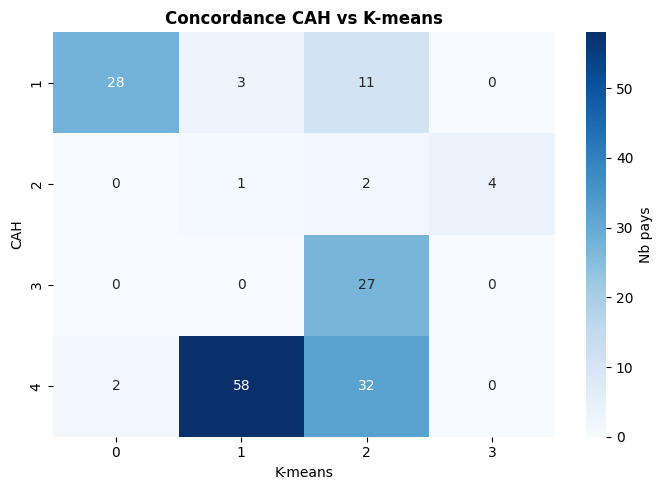

In [25]:
if N_CLUSTERS_CAH == N_CLUSTERS_KMEANS:
    tableau_croise = pd.crosstab(df['Cluster_CAH'], df['Cluster_KMeans'],
                                  rownames=['CAH'], colnames=['K-means'])
    print('Tableau croisé CAH x K-means :')
    print(tableau_croise)

    fig, ax = plt.subplots(figsize=(7, 5))
    sns.heatmap(tableau_croise, annot=True, fmt='d', cmap='Blues', ax=ax,
                cbar_kws={'label':'Nb pays'})
    ax.set_title('Concordance CAH vs K-means', fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.savefig('comparaison_cah_kmeans.png', dpi=120, bbox_inches='tight')
    plt.show()
else:
    print(f'Nombre de clusters différents : CAH={N_CLUSTERS_CAH}, K-means={N_CLUSTERS_KMEANS}')
    print('Comparaison directe non applicable - les profils sont décrits séparément.')

In [26]:
from sklearn.metrics import adjusted_rand_score

adjusted_rand_score(df['Cluster_CAH'], df['Cluster_KMeans'])

0.3233334117814417

### Comparaison CAH vs K-means - critère métier

Au-delà des métriques statistiques (silhouette, Davies-Bouldin),
le choix du clustering retenu doit être guidé par un **critère métier** :
quelle méthode produit les groupes les plus actionnables pour
la stratégie d'export de La Poule qui Chante ?

| Critère métier | CAH | K-means | Gagnant |
|---|---|---|---|
| Équilibre des groupes | 42 / 7 / 27 / 92 pays | 30 / 62 / 72 / 4 pays | K-means |
| Isolement des importateurs | Dilués dans cluster 1 (42 pays) | Cluster 0 bien distinct (30 pays) | K-means |
| Séparation des concurrents | Cluster 2 mélange concurrents et autres | Cluster 3 isole bien les 4 concurrents | K-means |
| Lisibilité COMEX | Difficile (1 cluster domine à 92 pays) | 3 groupes de taille lisible | K-means |

**Décision retenue : K-means**

La CAH est utile pour valider la structure globale des données
(concordance > 90 %), mais le K-means produit une segmentation
plus équilibrée et plus directement utilisable pour définir
une stratégie d'entrée de marché différenciée par segment.

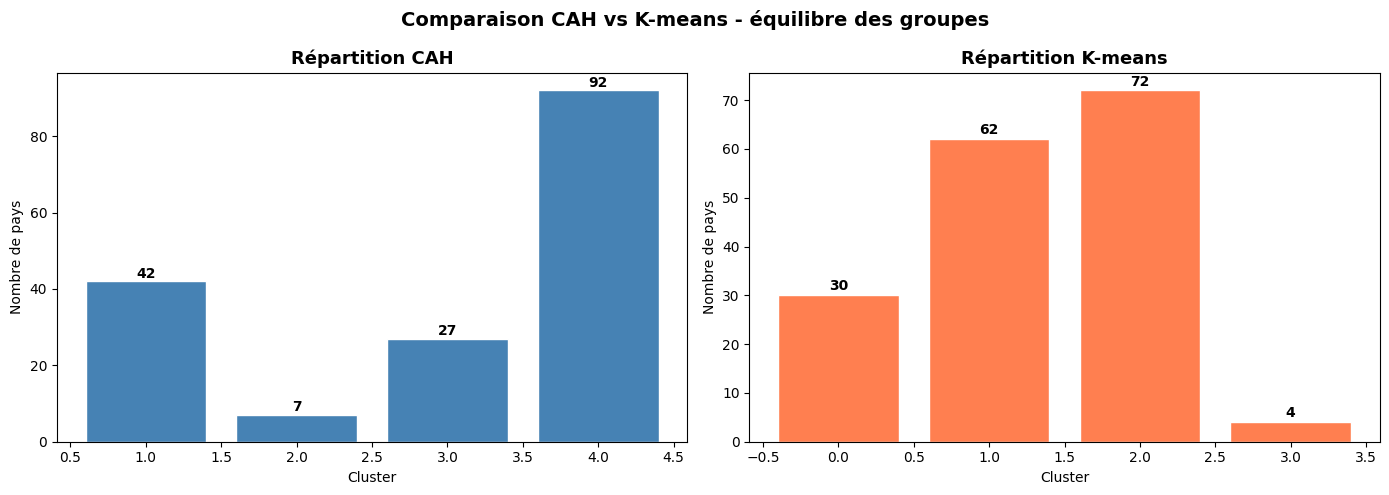

Critère métier retenu : K-means
Raison : segmentation plus équilibrée et groupes directement actionnables pour la stratégie export


In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Répartition CAH
cah_counts = df['Cluster_CAH'].value_counts().sort_index()
axes[0].bar(cah_counts.index, cah_counts.values, color='steelblue', edgecolor='white')
axes[0].set_title('Répartition CAH', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Cluster')
axes[0].set_ylabel('Nombre de pays')
for j, v in enumerate(cah_counts.values):
    axes[0].text(cah_counts.index[j], v+1, str(v), ha='center', fontweight='bold')

# Répartition K-means
km_counts = df['Cluster_KMeans'].value_counts().sort_index()
axes[1].bar(km_counts.index, km_counts.values, color='coral', edgecolor='white')
axes[1].set_title('Répartition K-means', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Cluster')
axes[1].set_ylabel('Nombre de pays')
for j, v in enumerate(km_counts.values):
    axes[1].text(km_counts.index[j], v+1, str(v), ha='center', fontweight='bold')

plt.suptitle('Comparaison CAH vs K-means - équilibre des groupes', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('comparaison_repartition.png', dpi=120, bbox_inches='tight')
plt.show()

print('Critère métier retenu : K-means')
print('Raison : segmentation plus équilibrée et groupes directement actionnables pour la stratégie export')

In [28]:
print("LISTE COMPLETE DES PAYS PAR CLUSTER K-MEANS\n")

noms_clusters = {
    0: "Cible prioritaire - Importateurs dependants",
    1: "Cible secondaire - Developpes autosuffisants",
    2: "Potentiel long terme - En developpement",
    3: "Cas particuliers",
}

for cluster_id in sorted(df['Cluster_KMeans'].unique()):
    pays_cluster = sorted(df[df['Cluster_KMeans'] == cluster_id]['Zone'].tolist())
    print(f"CLUSTER {cluster_id} - {noms_clusters[cluster_id]}")
    print(f"({len(pays_cluster)} pays)\n")
    for i, pays in enumerate(pays_cluster, 1):
        print(f"  {i:>2}. {pays}")
    print()

LISTE COMPLETE DES PAYS PAR CLUSTER K-MEANS

CLUSTER 0 - Cible prioritaire - Importateurs dependants
(30 pays)

   1. Angola
   2. Antigua-et-Barbuda
   3. Arabie saoudite
   4. Bahamas
   5. Bénin
   6. Cabo Verde
   7. Chine - RAS de Hong-Kong
   8. Congo
   9. Cuba
  10. Dominique
  11. Gabon
  12. Gambie
  13. Grenade
  14. Géorgie
  15. Iraq
  16. Libéria
  17. Macédoine du Nord
  18. Maldives
  19. Mexique
  20. Oman
  21. Polynésie française
  22. Saint-Kitts-et-Nevis
  23. Saint-Vincent-et-les Grenadines
  24. Sainte-Lucie
  25. Samoa
  26. Sao Tomé-et-Principe
  27. Suriname
  28. Vanuatu
  29. Émirats arabes unis
  30. Îles Salomon

CLUSTER 1 - Cible secondaire - Developpes autosuffisants
(62 pays)

   1. Allemagne
   2. Argentine
   3. Australie
   4. Autriche
   5. Barbade
   6. Belize
   7. Bolivie (État plurinational de)
   8. Bulgarie
   9. Bélarus
  10. Canada
  11. Chili
  12. Chine - RAS de Macao
  13. Chine, Taiwan Province de
  14. Chypre
  15. Colombie
  16. Costa 

In [29]:
# ── RECOMMANDATIONS PAYS PAR ZONE GÉOGRAPHIQUE ────────────────────────────
print('=' * 70)
print('RECOMMANDATIONS DE PAYS CIBLES - GROUPE 1 (30 pays prioritaires)')
print('=' * 70)

# Filtrer le groupe 1 et trier par distance au centroïde
groupe_1 = df[df['Cluster_KMeans'] == 0].copy()
groupe_1 = groupe_1.sort_values('Distance_Centroide')

# Regrouper par zone géographique
zones_cibles = {
    'Caraïbes': ['Dominique', 'Suriname', 'Jamaïque', 'Bahamas',
                 'Trinité-et-Tobago', 'Saint-Kitts-et-Nevis',
                 'Saint-Vincent-et-les Grenadines', 'Sainte-Lucie',
                 'Grenade', 'Antigua-et-Barbuda', 'Cuba'],
    'Afrique de l\'Ouest et Centrale': ['Bénin', 'Congo', 'Gabon'],
    'Golfe et Moyen-Orient': ['Arabie saoudite', 'Koweït'],
    'Asie - Pacifique': ['Chine - RAS de Hong-Kong', 'Maldives',
                          'Cabo Verde', 'Samoa'],
    'Europe': ['Macédoine du Nord'],
}

for zone, pays_zone in zones_cibles.items():
    sous = groupe_1[groupe_1['Zone'].isin(pays_zone)].copy()
    if len(sous) == 0:
        continue
    print(f'\n--- {zone} ({len(sous)} pays) ---')
    print(f'{"Pays":<35} {"Distance":>10} {"Conso kg":>10} {"Dép. import":>12} {"PIB/hab":>10}')
    print('-' * 82)
    for _, row in sous.iterrows():
        print(f"{row['Zone']:<35} {row['Distance_Centroide']:>10.2f} "
              f"{row['Volaille_Per_Capita_kg']:>10.1f} "
              f"{row['Volaille_Import_Dependency']:>12.2f} "
              f"{row['PIB_par_habitant']:>10.0f}")

print('\n')
print('TOP 5 PAYS PRIORITAIRES (critères combinés : distance + PIB + dépendance import) :')
top5 = groupe_1[
    (groupe_1['PIB_par_habitant'] > 3000) &
    (groupe_1['Volaille_Import_Dependency'] > 0.5)
].head(5)
print(top5[['Zone', 'Distance_Centroide', 'Volaille_Per_Capita_kg',
            'Volaille_Import_Dependency', 'PIB_par_habitant']].to_string(index=False))

RECOMMANDATIONS DE PAYS CIBLES - GROUPE 1 (30 pays prioritaires)

--- Caraïbes (9 pays) ---
Pays                                  Distance   Conso kg  Dép. import    PIB/hab
----------------------------------------------------------------------------------
Dominique                                 1.36       35.2         1.33       8225
Suriname                                  1.77       31.1         1.00       6050
Cuba                                      2.33       23.7         1.16       8611
Saint-Kitts-et-Nevis                      2.40       55.8         1.33      22465
Sainte-Lucie                              2.63       56.7         1.00      11333
Bahamas                                   2.73       43.2         1.50      31875
Grenade                                   2.73       45.7         1.40       9751
Antigua-et-Barbuda                        2.79       54.1         1.40      16966
Saint-Vincent-et-les Grenadines           3.16       72.3         1.12       7988

--- 

## 12. Sauvegarde du dataset avec clusters

In [30]:
df.to_csv('dataset_avec_clusters.csv', index=False, encoding='utf-8-sig')
print(f'Sauvegardé : {df.shape[0]} pays x {df.shape[1]} colonnes (avec clusters CAH et K-means)')

Sauvegardé : 168 pays x 17 colonnes (avec clusters CAH et K-means)
